<a href="https://colab.research.google.com/github/guigadesouza11/Comunica-es-Moveis/blob/main/Projeto_II.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

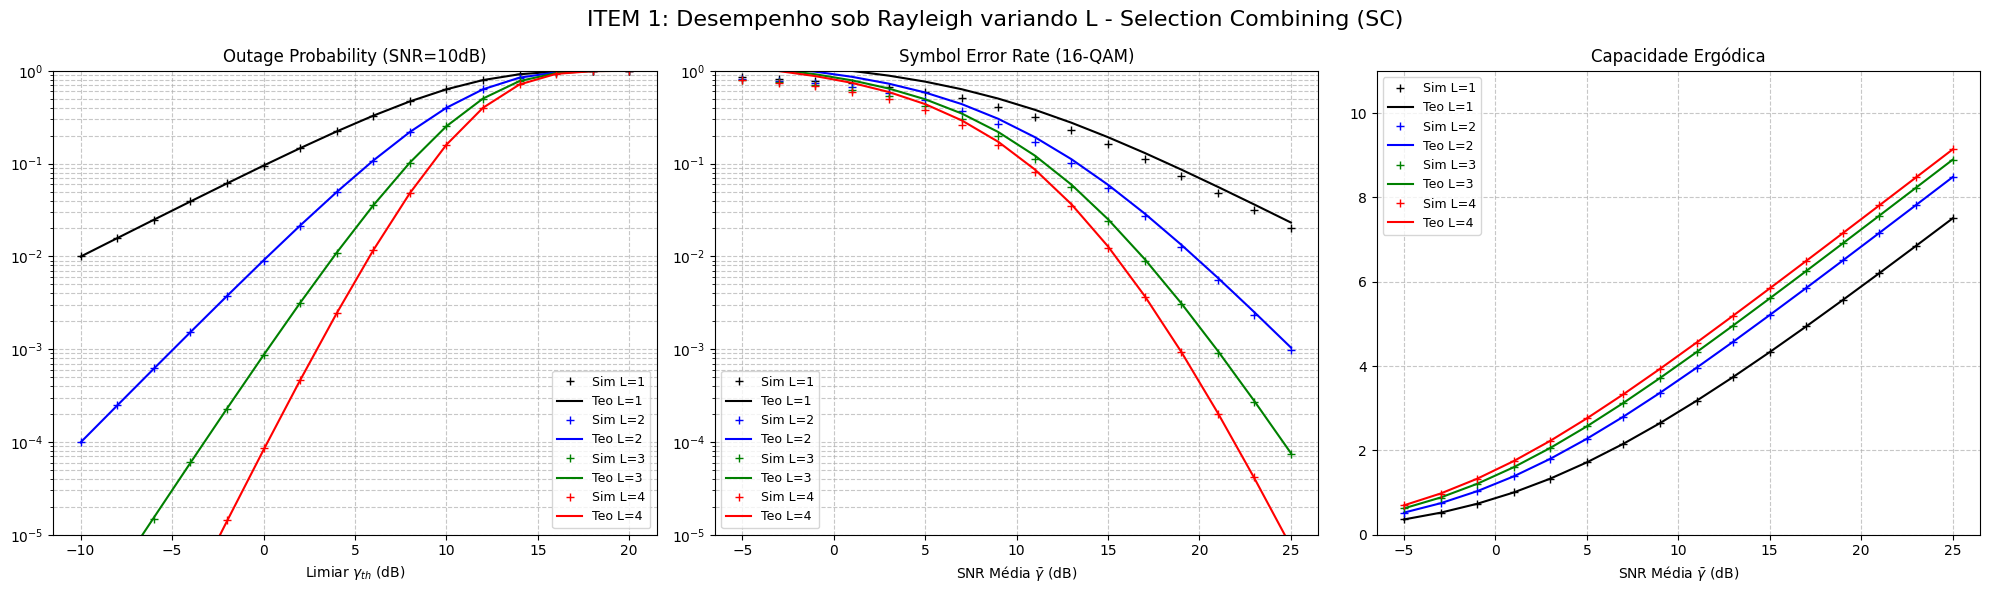

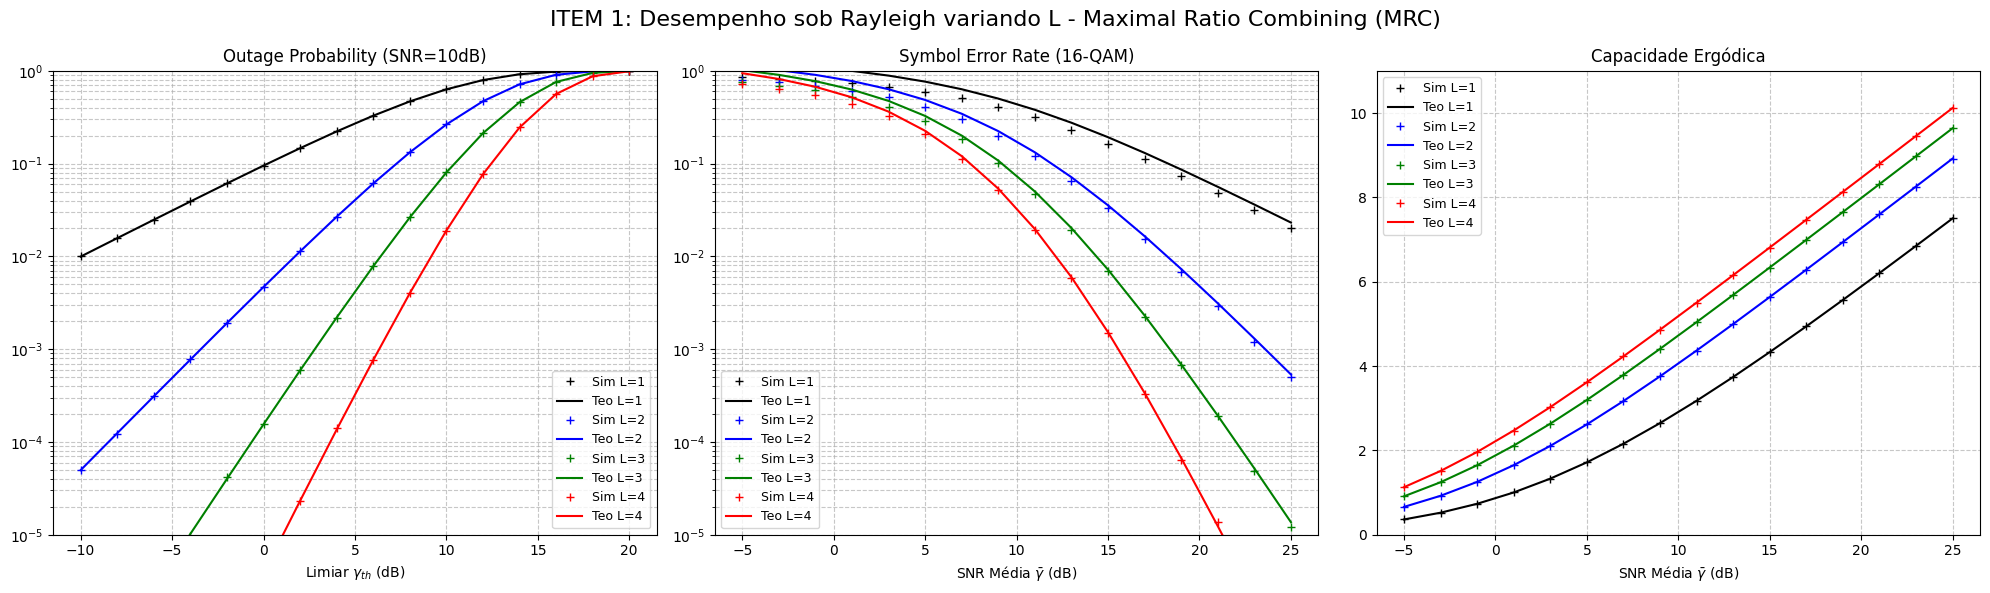

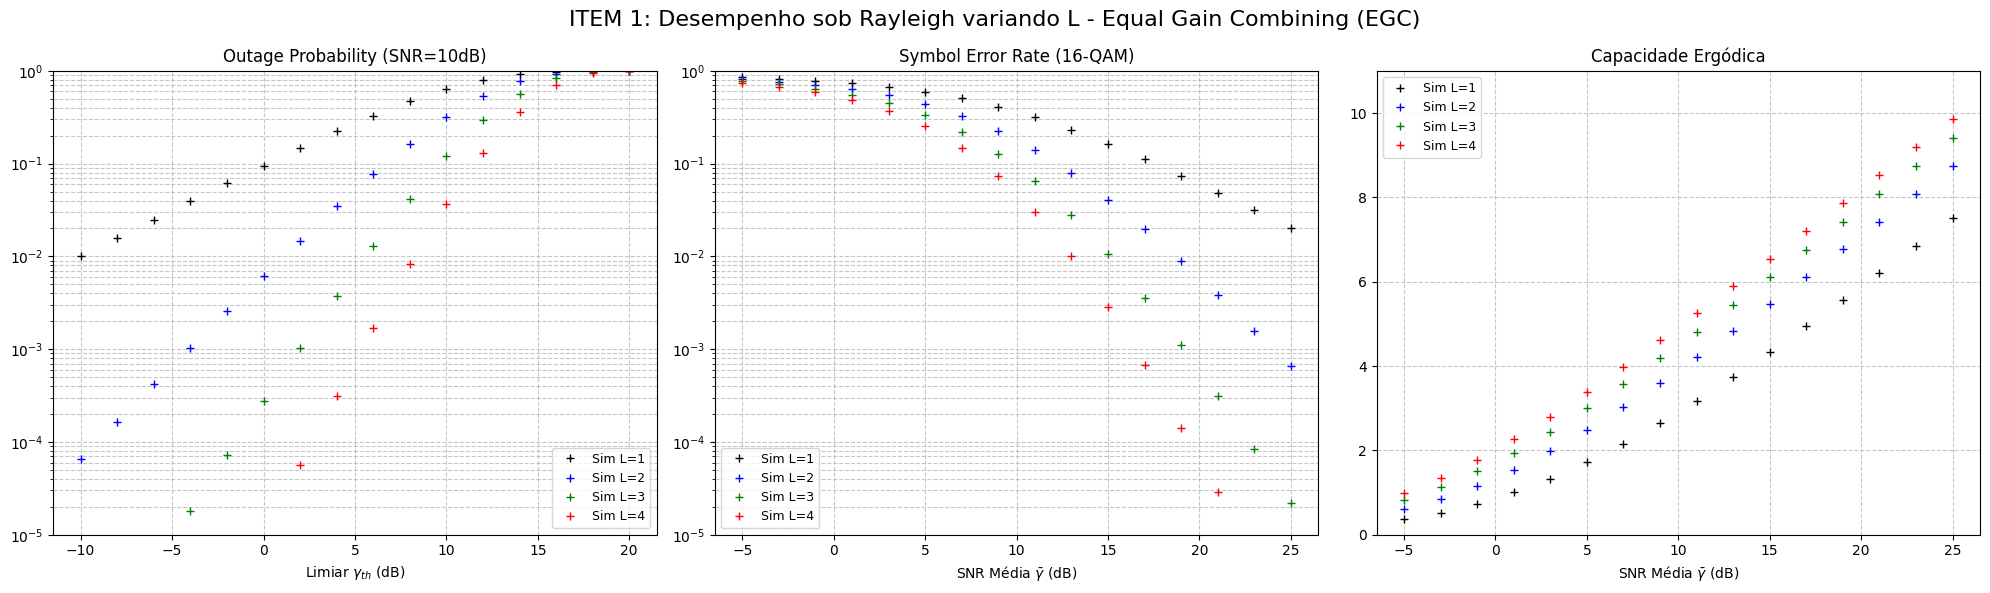

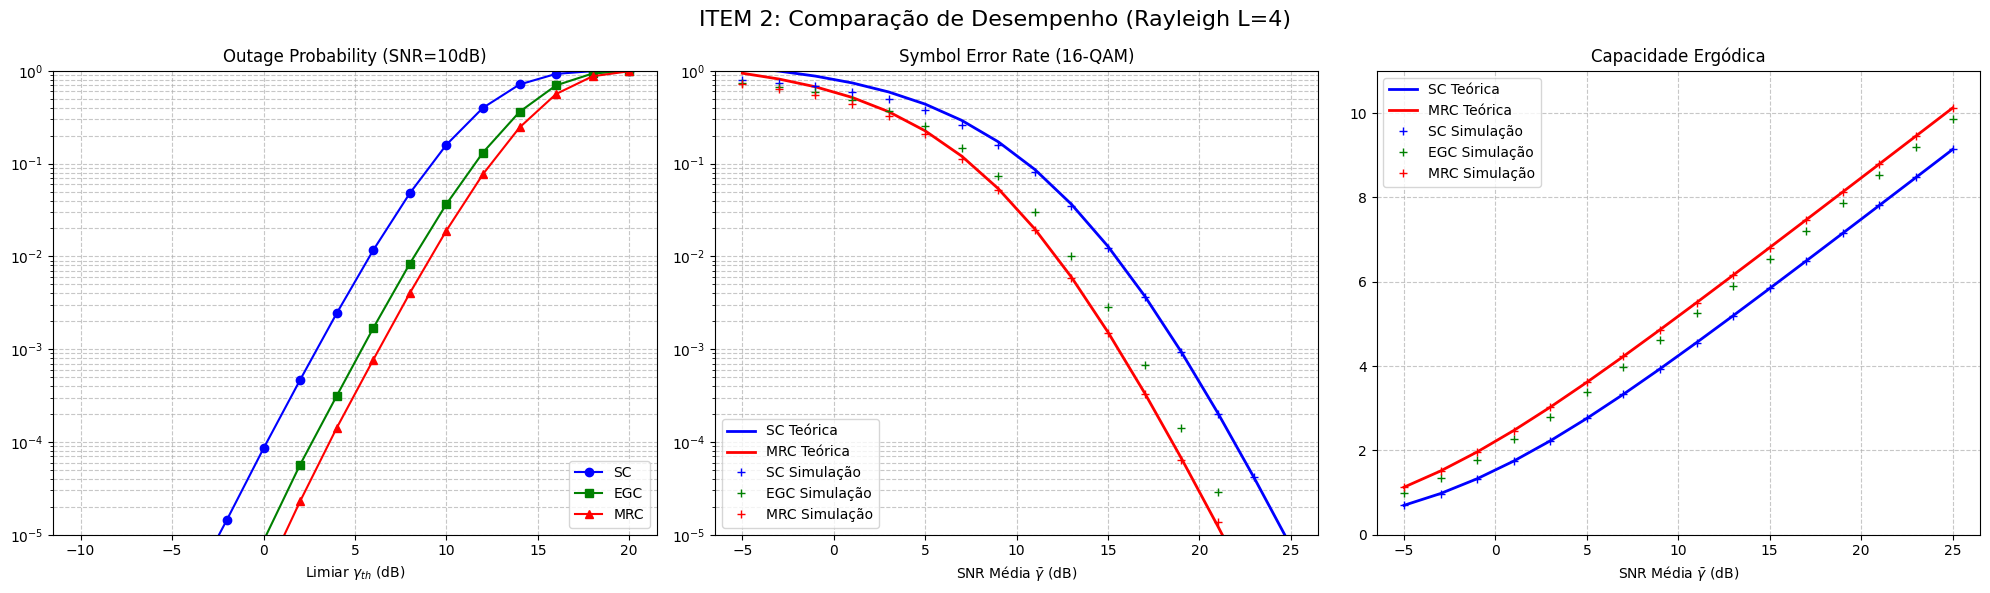

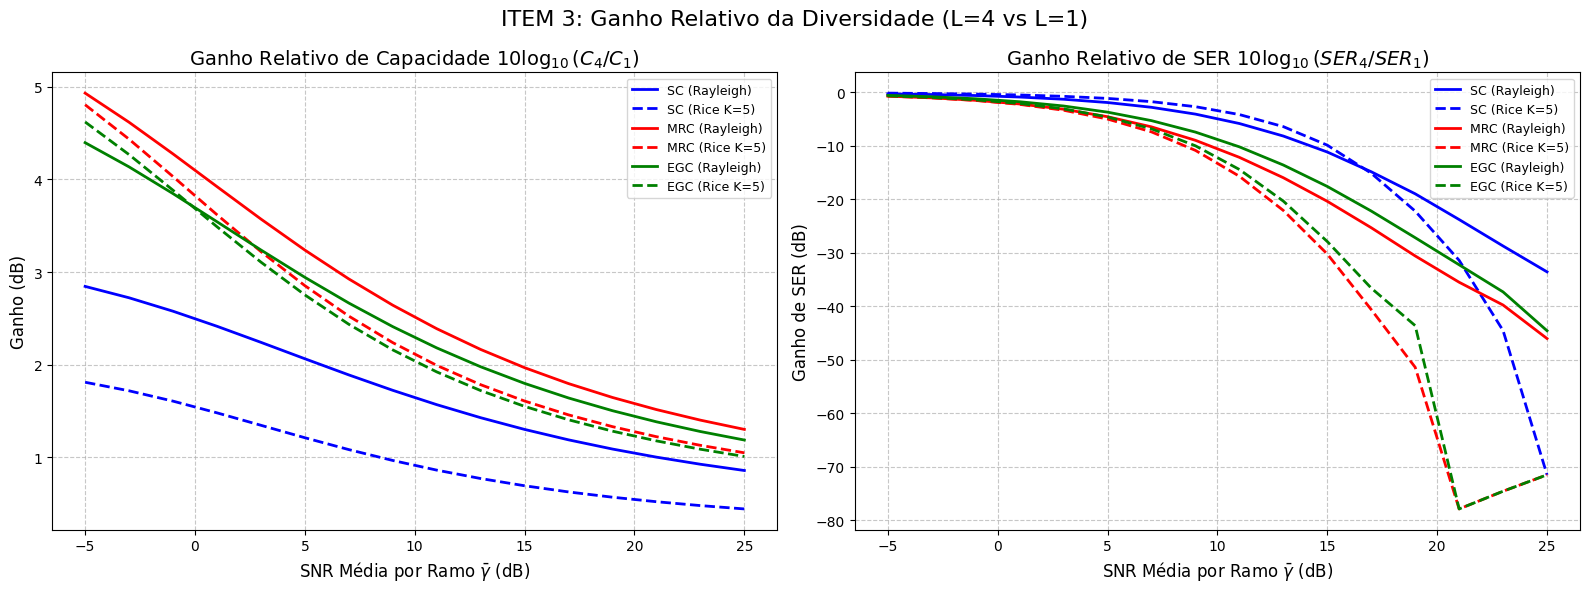

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.special as sp
import math

def gerar_constelacao(M):
    L = int(np.sqrt(M))
    d = np.sqrt(3 / (2 * (M - 1)))
    eixo = d * np.arange(-(L - 1), L, 2)
    I, Q = np.meshgrid(eixo, eixo)
    return (I + 1j * Q).flatten()

def gerar_beta_rice(K, size):
    mu = np.sqrt(K / (K + 1))
    sigma = np.sqrt(1 / (2 * (K + 1)))
    x = np.random.normal(mu, sigma, size)
    y = np.random.normal(0, sigma, size)
    return np.sqrt(x**2 + y**2)

def sep_teo_sc(L, gamma_bar, M):
    a_M = 4 * (1 - 1/np.sqrt(M))
    b_M = 3 / (M - 1)
    sep = 0
    for l in range(L):
        c_M = np.sqrt((b_M * gamma_bar / (2 * (l + 1))) / (1 + b_M * gamma_bar / (2 * (l + 1))))
        sep += math.comb(L - 1, l) * ((-1)**l) * (L / (2 * (l + 1))) * (1 - c_M)
    return a_M * sep

def sep_teo_mrc(L, gamma_bar, M):
    a_M = 4 * (1 - 1/np.sqrt(M))
    b_M = 3 / (M - 1)
    mu = np.sqrt((b_M * gamma_bar / 2) / (1 + b_M * gamma_bar / 2))
    sep = sum(math.comb(L - 1 + k, k) * (((1 + mu) / 2)**k) for k in range(L))
    return a_M * (((1 - mu) / 2)**L) * sep

def cap_teo_sc(L, gamma_bar):
    C = 0
    for k in range(L):
        arg = (k + 1) / gamma_bar
        C += math.comb(L - 1, k) * ((-1)**k / (k + 1)) * np.exp(arg) * sp.exp1(arg)
    return (L / np.log(2)) * C

def cap_teo_mrc(L, gamma_bar):
    arg = 1 / gamma_bar
    C = sum(sp.expn(L - k + 1, arg) for k in range(1, L + 1))
    return (1 / np.log(2)) * np.exp(arg) * C

def out_teo_sc(L, gamma_th, gamma_bar):
    return (1 - np.exp(-gamma_th / gamma_bar))**L

def out_teo_mrc(L, gamma_th, gamma_bar):
    out = 0
    for k in range(L):
        out += (1 / math.factorial(k)) * (gamma_th / gamma_bar)**k * np.exp(-gamma_th / gamma_bar)
    return 1 - out


N_t = 10**7
M = 16
C = gerar_constelacao(M)
L_vetor = [1, 2, 3, 4]
L_comp = 4
K_rice = 5

snr_dB_vetor = np.arange(-5, 26, 2)
snr_linear_vetor = 10**(snr_dB_vetor / 10)
limiares_dB = np.arange(-10, 21, 2)
limiares_linear = 10**(limiares_dB / 10)
gamma_bar_outage = 10**(10 / 10)


res_outage = {c: {L: [] for L in L_vetor} for c in ['sc', 'mrc', 'egc']}
res_cap = {c: {L: [] for L in L_vetor} for c in ['sc', 'mrc', 'egc']}
res_ser = {c: {L: [] for L in L_vetor} for c in ['sc', 'mrc', 'egc']}


cap_ray_L1, ser_ray_L1 = [], []
cap_rice_L1, ser_rice_L1 = [], []
cap_rice = {c: [] for c in ['sc', 'mrc', 'egc']}
ser_rice = {c: [] for c in ['sc', 'mrc', 'egc']}

indices_tx = np.random.randint(0, M, size=N_t)
S_t = C[indices_tx]


beta_ray_matriz = np.sqrt(np.random.normal(0, np.sqrt(0.5), (max(L_vetor), N_t))**2 +
                          np.random.normal(0, np.sqrt(0.5), (max(L_vetor), N_t))**2)
beta2_ray_matriz = beta_ray_matriz**2

beta_rice_matriz = gerar_beta_rice(K_rice, (L_comp, N_t))
beta2_rice_matriz = beta_rice_matriz**2


for L in L_vetor:
    b = beta_ray_matriz[:L, :]
    b2 = beta2_ray_matriz[:L, :]
    g_sc = np.max(gamma_bar_outage * b2, axis=0)
    g_mrc = np.sum(gamma_bar_outage * b2, axis=0)
    g_egc = ((np.sum(b, axis=0)**2) / L) * gamma_bar_outage

    for th in limiares_linear:
        res_outage['sc'][L].append(np.sum(g_sc <= th) / N_t)
        res_outage['mrc'][L].append(np.sum(g_mrc <= th) / N_t)
        res_outage['egc'][L].append(np.sum(g_egc <= th) / N_t)

for gamma_bar in snr_linear_vetor:
    sigma_n = np.sqrt(1 / (2 * gamma_bar))
    n = np.random.normal(0, sigma_n, N_t) + 1j * np.random.normal(0, sigma_n, N_t)

    for L in L_vetor:
        b = beta_ray_matriz[:L, :]
        b2 = beta2_ray_matriz[:L, :]

        g_sc = np.max(gamma_bar * b2, axis=0)
        g_mrc = np.sum(gamma_bar * b2, axis=0)
        g_egc = ((np.sum(b, axis=0)**2) / L) * gamma_bar

        res_cap['sc'][L].append(np.mean(np.log2(1 + g_sc)))
        res_cap['mrc'][L].append(np.mean(np.log2(1 + g_mrc)))
        res_cap['egc'][L].append(np.mean(np.log2(1 + g_egc)))

        for comb, g_eq in zip(['sc', 'mrc', 'egc'], [g_sc, g_mrc, g_egc]):
            b_eq = np.sqrt(g_eq / gamma_bar)
            dist = np.abs((b_eq * S_t + n)[:, None] - (b_eq[:, None] * C[None, :]))**2
            res_ser[comb][L].append(np.sum(S_t != C[np.argmin(dist, axis=1)]) / N_t)

    cap_ray_L1.append(res_cap['mrc'][1][-1])
    ser_ray_L1.append(res_ser['mrc'][1][-1])
    g_rice_1 = gamma_bar * beta2_rice_matriz[0, :]
    cap_rice_L1.append(np.mean(np.log2(1 + g_rice_1)))
    b_eq_1 = np.sqrt(g_rice_1 / gamma_bar)
    dist_1 = np.abs((b_eq_1 * S_t + n)[:, None] - (b_eq_1[:, None] * C[None, :]))**2
    ser_rice_L1.append(np.sum(S_t != C[np.argmin(dist_1, axis=1)]) / N_t)

    g_rice_sc = np.max(gamma_bar * beta2_rice_matriz, axis=0)
    g_rice_mrc = np.sum(gamma_bar * beta2_rice_matriz, axis=0)
    g_rice_egc = ((np.sum(beta_rice_matriz, axis=0)**2) / L_comp) * gamma_bar

    for comb, g_eq in zip(['sc', 'mrc', 'egc'], [g_rice_sc, g_rice_mrc, g_rice_egc]):
        cap_rice[comb].append(np.mean(np.log2(1 + g_eq)))
        b_eq = np.sqrt(g_eq / gamma_bar)
        dist = np.abs((b_eq * S_t + n)[:, None] - (b_eq[:, None] * C[None, :]))**2
        ser_rice[comb].append(np.sum(S_t != C[np.argmin(dist, axis=1)]) / N_t)

cores = {1: 'k', 2: 'b', 3: 'g', 4: 'r'}
titulos = {'sc': 'Selection Combining (SC)', 'mrc': 'Maximal Ratio Combining (MRC)', 'egc': 'Equal Gain Combining (EGC)'}

for comb in ['sc', 'mrc', 'egc']:
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(f'ITEM 1: Desempenho sob Rayleigh variando L - {titulos[comb]}', fontsize=16)

    for L in L_vetor:
        c = cores[L]
        # Outage
        axs[0].semilogy(limiares_dB, res_outage[comb][L], c + '+', markersize=6, label=f'Sim L={L}')
        if comb == 'sc':
            axs[0].semilogy(limiares_dB, [out_teo_sc(L, th, gamma_bar_outage) for th in limiares_linear], c + '-', label=f'Teo L={L}')
        elif comb == 'mrc':
            axs[0].semilogy(limiares_dB, [out_teo_mrc(L, th, gamma_bar_outage) for th in limiares_linear], c + '-', label=f'Teo L={L}')

        # SER
        axs[1].semilogy(snr_dB_vetor, res_ser[comb][L], c + '+', markersize=6, label=f'Sim L={L}')
        if comb == 'sc':
            axs[1].semilogy(snr_dB_vetor, [sep_teo_sc(L, g, M) for g in snr_linear_vetor], c + '-', label=f'Teo L={L}')
        elif comb == 'mrc':
            axs[1].semilogy(snr_dB_vetor, [sep_teo_mrc(L, g, M) for g in snr_linear_vetor], c + '-', label=f'Teo L={L}')

        # Capacidade
        axs[2].plot(snr_dB_vetor, res_cap[comb][L], c + '+', markersize=6, label=f'Sim L={L}')
        if comb == 'sc':
            axs[2].plot(snr_dB_vetor, [cap_teo_sc(L, g) for g in snr_linear_vetor], c + '-', label=f'Teo L={L}')
        elif comb == 'mrc':
            axs[2].plot(snr_dB_vetor, [cap_teo_mrc(L, g) for g in snr_linear_vetor], c + '-', label=f'Teo L={L}')

    axs[0].set_title('Outage Probability (SNR=10dB)')
    axs[0].set_xlabel(r'Limiar $\gamma_{th}$ (dB)')
    axs[0].set_ylim(1e-5, 1)
    axs[0].grid(True, which='both', linestyle='--', alpha=0.7)
    axs[0].legend(loc='lower right', fontsize=9)

    axs[1].set_title('Symbol Error Rate (16-QAM)')
    axs[1].set_xlabel(r'SNR Média $\bar{\gamma}$ (dB)')
    axs[1].set_ylim(1e-5, 1)
    axs[1].grid(True, which='both', linestyle='--', alpha=0.7)
    axs[1].legend(loc='lower left', fontsize=9)

    axs[2].set_title('Capacidade Ergódica')
    axs[2].set_xlabel(r'SNR Média $\bar{\gamma}$ (dB)')
    axs[2].set_ylim(0, 11)
    axs[2].grid(True, linestyle='--', alpha=0.7)
    axs[2].legend(loc='upper left', fontsize=9)
    plt.tight_layout()

fig2, axs2 = plt.subplots(1, 3, figsize=(20, 6))
fig2.suptitle(f'ITEM 2: Comparação de Desempenho (Rayleigh L={L_comp})', fontsize=16)

# Outage L=4
axs2[0].semilogy(limiares_dB, res_outage['sc'][L_comp], 'b-o', label='SC')
axs2[0].semilogy(limiares_dB, res_outage['egc'][L_comp], 'g-s', label='EGC')
axs2[0].semilogy(limiares_dB, res_outage['mrc'][L_comp], 'r-^', label='MRC')
axs2[0].set_title('Outage Probability (SNR=10dB)')
axs2[0].set_xlabel(r'Limiar $\gamma_{th}$ (dB)')
axs2[0].set_ylim(1e-5, 1)
axs2[0].grid(True, which='both', linestyle='--', alpha=0.7)
axs2[0].legend(loc='lower right')

# SER L=4
axs2[1].semilogy(snr_dB_vetor, [sep_teo_sc(L_comp, g, M) for g in snr_linear_vetor], 'b-', linewidth=2, label='SC Teórica')
axs2[1].semilogy(snr_dB_vetor, [sep_teo_mrc(L_comp, g, M) for g in snr_linear_vetor], 'r-', linewidth=2, label='MRC Teórica')
axs2[1].semilogy(snr_dB_vetor, res_ser['sc'][L_comp], 'b+', markersize=6, label='SC Simulação')
axs2[1].semilogy(snr_dB_vetor, res_ser['egc'][L_comp], 'g+', markersize=6, label='EGC Simulação')
axs2[1].semilogy(snr_dB_vetor, res_ser['mrc'][L_comp], 'r+', markersize=6, label='MRC Simulação')
axs2[1].set_title('Symbol Error Rate (16-QAM)')
axs2[1].set_xlabel(r'SNR Média $\bar{\gamma}$ (dB)')
axs2[1].set_ylim(1e-5, 1)
axs2[1].grid(True, which='both', linestyle='--', alpha=0.7)
axs2[1].legend(loc='lower left')

# Capacidade L=4
axs2[2].plot(snr_dB_vetor, [cap_teo_sc(L_comp, g) for g in snr_linear_vetor], 'b-', linewidth=2, label='SC Teórica')
axs2[2].plot(snr_dB_vetor, [cap_teo_mrc(L_comp, g) for g in snr_linear_vetor], 'r-', linewidth=2, label='MRC Teórica')
axs2[2].plot(snr_dB_vetor, res_cap['sc'][L_comp], 'b+', markersize=6, label='SC Simulação')
axs2[2].plot(snr_dB_vetor, res_cap['egc'][L_comp], 'g+', markersize=6, label='EGC Simulação')
axs2[2].plot(snr_dB_vetor, res_cap['mrc'][L_comp], 'r+', markersize=6, label='MRC Simulação')
axs2[2].set_title('Capacidade Ergódica')
axs2[2].set_xlabel(r'SNR Média $\bar{\gamma}$ (dB)')
axs2[2].set_ylim(0, 11)
axs2[2].grid(True, linestyle='--', alpha=0.7)
axs2[2].legend(loc='upper left')
plt.tight_layout()

fig_g, axs_g = plt.subplots(1, 2, figsize=(16, 6))
fig_g.suptitle(f'ITEM 3: Ganho Relativo da Diversidade (L=4 vs L=1)', fontsize=16)
eps = 1e-10

for comb, cor in zip(['sc', 'mrc', 'egc'], ['b', 'r', 'g']):
    g_cap_ray = 10 * np.log10(np.array(res_cap[comb][L_comp]) / np.array(cap_ray_L1))
    g_ser_ray = 10 * np.log10(np.maximum(np.array(res_ser[comb][L_comp]), eps) / np.maximum(np.array(ser_ray_L1), eps))

    axs_g[0].plot(snr_dB_vetor, g_cap_ray, color=cor, linestyle='-', linewidth=2, label=f'{comb.upper()} (Rayleigh)')
    axs_g[1].plot(snr_dB_vetor, g_ser_ray, color=cor, linestyle='-', linewidth=2, label=f'{comb.upper()} (Rayleigh)')

    g_cap_rice = 10 * np.log10(np.array(cap_rice[comb]) / np.array(cap_rice_L1))
    g_ser_rice = 10 * np.log10(np.maximum(np.array(ser_rice[comb]), eps) / np.maximum(np.array(ser_rice_L1), eps))

    axs_g[0].plot(snr_dB_vetor, g_cap_rice, color=cor, linestyle='--', linewidth=2, label=f'{comb.upper()} (Rice K={K_rice})')
    axs_g[1].plot(snr_dB_vetor, g_ser_rice, color=cor, linestyle='--', linewidth=2, label=f'{comb.upper()} (Rice K={K_rice})')

axs_g[0].set_title(r'Ganho Relativo de Capacidade $10\log_{10}(C_4/C_1)$', fontsize=14)
axs_g[0].set_xlabel(r'SNR Média por Ramo $\bar{\gamma}$ (dB)', fontsize=12)
axs_g[0].set_ylabel('Ganho (dB)', fontsize=12)
axs_g[0].grid(True, linestyle='--', alpha=0.7)
axs_g[0].legend(fontsize=9)
axs_g[1].set_title(r'Ganho Relativo de SER $10\log_{10}(SER_4/SER_1)$', fontsize=14)
axs_g[1].set_xlabel(r'SNR Média por Ramo $\bar{\gamma}$ (dB)', fontsize=12)
axs_g[1].set_ylabel('Ganho de SER (dB)', fontsize=12)
axs_g[1].grid(True, linestyle='--', alpha=0.7)
axs_g[1].legend(fontsize=9)

plt.tight_layout()
plt.show()